/tmp/ipykernel_28202/61450052.py:38: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap("YlOrRd")
/tmp/ipykernel_28202/61450052.py:117: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  plt.cm.get_cmap("YlOrRd")(


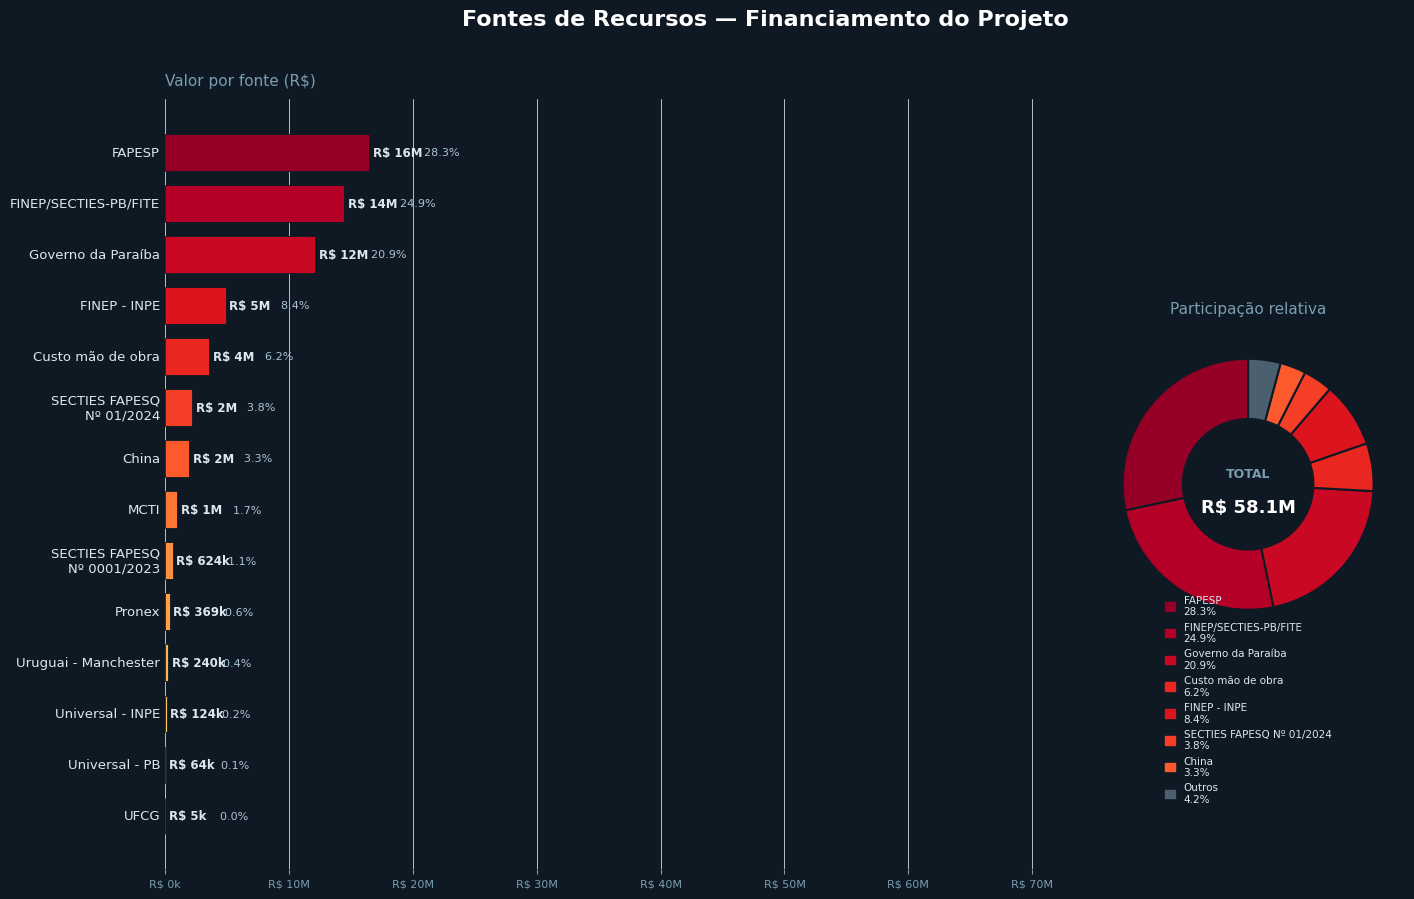

In [1]:
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

# --- Dados ---
dados = {
    "FAPESP": 16_471_732,
    "FINEP/SECTIES-PB/FITE": 14_480_156,
    "Governo da Paraíba": 12_133_800,
    "Custo mão de obra": 3_580_814,
    "FINEP - INPE": 4_900_000,
    "SECTIES FAPESQ\nNº 01/2024": 2_195_000,
    "China": 1_935_000,
    "MCTI": 1_000_000,
    "SECTIES FAPESQ\nNº 0001/2023": 624_000,
    "Pronex": 368_900,
    "Uruguai - Manchester": 240_000,
    "Universal - INPE": 124_000,
    "Universal - PB": 64_000,
    "UFCG": 5_000,
}

fontes = list(dados.keys())
valores = list(dados.values())
total = sum(valores)
percentuais = [v / total * 100 for v in valores]

# Ordenar por valor
ordem = np.argsort(valores)
fontes_ord = [fontes[i] for i in ordem]
valores_ord = [valores[i] for i in ordem]
perc_ord = [percentuais[i] for i in ordem]

# --- Paleta de cores ---
# Gradiente de azul-escuro a ciano, destaques para os maiores
n = len(fontes_ord)
cmap = plt.cm.get_cmap("YlOrRd")
cores = [cmap(0.2 + 0.75 * (i / (n - 1))) for i in range(n)]

# --- Layout ---
fig = plt.figure(figsize=(16, 10), facecolor="#0f1923")
fig.patch.set_facecolor("#0f1923")

# Grid: barra horizontal à esquerda, donut à direita
gs = fig.add_gridspec(1, 2, width_ratios=[2.8, 1], wspace=0.08)
ax_bar = fig.add_subplot(gs[0])
ax_donut = fig.add_subplot(gs[1])

for ax in [ax_bar, ax_donut]:
    ax.set_facecolor("#0f1923")

# ── Gráfico de barras horizontais ──────────────────────────────────────────
bars = ax_bar.barh(
    range(n),
    valores_ord,
    color=cores,
    edgecolor="#0f1923",
    linewidth=0.6,
    height=0.72,
)

# Grade sutil
ax_bar.xaxis.set_major_formatter(
    mticker.FuncFormatter(
        lambda x, _: f"R$ {x / 1e6:.0f}M" if x >= 1e6 else f"R$ {x / 1e3:.0f}k"
    )
)
ax_bar.xaxis.grid(True, color="#ffffff18", linewidth=0.5, zorder=0)
ax_bar.set_axisbelow(True)

# Rótulos no eixo Y
ax_bar.set_yticks(range(n))
ax_bar.set_yticklabels(fontes_ord, fontsize=9.5, color="#dce8f0", va="center")

# Valor + % no final de cada barra
for i, (v, p) in enumerate(zip(valores_ord, perc_ord)):
    label_valor = f"R$ {v / 1e6:.0f}M" if v >= 1e6 else f"R$ {v / 1e3:.0f}k"
    label_perc = f"  {p:.1f}%"
    ax_bar.text(
        v + total * 0.005,
        i,
        label_valor,
        va="center",
        ha="left",
        fontsize=8.5,
        color="#dce8f0",
        fontweight="bold",
    )
    ax_bar.text(
        v + total * 0.005 + total * 0.062,
        i,
        label_perc,
        va="center",
        ha="left",
        fontsize=8,
        color="#aac4d4",
    )

ax_bar.set_xlim(0, total * 1.22)
ax_bar.tick_params(axis="x", colors="#7a9db0", labelsize=8)
ax_bar.tick_params(axis="y", length=0)
for spine in ax_bar.spines.values():
    spine.set_visible(False)

# ── Donut ──────────────────────────────────────────────────────────────────
# Agrupar menores em "Outros" para clareza
threshold = 0.02  # < 2% vai para "Outros"
fatias_val, fatias_label, fatias_cor = [], [], []
outros_val = 0
outros_items = []

for f, v, c in zip(
    fontes,
    valores,
    [
        plt.cm.get_cmap("YlOrRd")(
            0.2
            + 0.75 * (list(np.argsort(valores)).index(list(valores).index(v)) / (n - 1))
        )
        for v in valores
    ],
):
    if v / total >= threshold:
        fatias_val.append(v)
        fatias_label.append(f.replace("\n", " "))
        fatias_cor.append(c)
    else:
        outros_val += v
        outros_items.append(f.replace("\n", " "))

if outros_val > 0:
    fatias_val.append(outros_val)
    fatias_label.append("Outros")
    fatias_cor.append("#4a6070")

wedge_props = dict(width=0.48, edgecolor="#0f1923", linewidth=1.5)
wedges, texts = ax_donut.pie(
    fatias_val,
    labels=None,
    colors=fatias_cor,
    wedgeprops=wedge_props,
    startangle=90,
)

# Centro do donut
ax_donut.text(
    0,
    0.08,
    "TOTAL",
    ha="center",
    va="center",
    fontsize=9,
    color="#7a9db0",
    fontweight="bold",
)
ax_donut.text(
    0,
    -0.18,
    f"R$ {total / 1e6:.1f}M",
    ha="center",
    va="center",
    fontsize=13,
    color="#ffffff",
    fontweight="bold",
)

# Legenda do donut
patches = [
    mpatches.Patch(color=c, label=f"{l}\n{v / total * 100:.1f}%")
    for l, v, c in zip(fatias_label, fatias_val, fatias_cor)
]
ax_donut.legend(
    handles=patches,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.55),
    fontsize=7.5,
    ncol=1,
    frameon=False,
    labelcolor="#dce8f0",
    handlelength=1.0,
    handleheight=0.9,
)

# ── Títulos ────────────────────────────────────────────────────────────────
fig.suptitle(
    "Fontes de Recursos — Financiamento do Projeto",
    fontsize=16,
    fontweight="bold",
    color="#ffffff",
    y=0.97,
)
ax_bar.set_title(
    "Valor por fonte (R$)", fontsize=11, color="#7a9db0", pad=10, loc="left"
)
ax_donut.set_title("Participação relativa", fontsize=11, color="#7a9db0", pad=10)

plt.savefig(
    "recursos_financiamento.png",
    dpi=160,
    bbox_inches="tight",
    facecolor=fig.get_facecolor(),
)